# Pronóstico del precio de bolsa: de los datos al modelo inicial

Este notebook reúne en un solo lugar todo el flujo de trabajo:

1. **Análisis** del precio y de las variables disponibles.
2. **Ingeniería de características**: rezagos, cambios semanales y variables de calendario.
3. **Selección de características** con métodos clásicos:
   - selección de variables originales: *best subset*, *forward*, *backward* e híbrido (*stepwise*);
   - penalización: Lasso, Ridge y Elastic Net;
   - reducción de dimensión: PCR y PLS.
4. **Modelo inicial**: XGBoost con las variables seleccionadas.

**Datos:** el panel diario ya consolidado por `00_consolidar_panel.py` (`data/panel_d.parquet`, 2015–2025).

**Partición temporal** (nunca se mezcla el futuro con el pasado):

| Periodo | Fechas | Uso |
|---|---|---|
| Desarrollo | 2015 – 2022 | análisis, selección de variables y entrenamiento |
| Prueba | 2023 – 2025 | solo para medir el desempeño final |

In [1]:
import warnings
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.decomposition import PCA
from sklearn.cross_decomposition import PLSRegression
from sklearn.linear_model import LinearRegression, LassoCV, RidgeCV, ElasticNetCV, lasso_path
from sklearn.model_selection import TimeSeriesSplit, cross_val_score
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.inspection import permutation_importance
import xgboost as xgb

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
plt.rcParams["figure.figsize"] = (13, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

OBJETIVO = "precio_ponderado"
FIN_DESARROLLO = "2022-12-31"
INICIO_PRUEBA = "2023-01-01"

# Validación cruzada que respeta el orden del tiempo: siempre entrena con el pasado y valida con el futuro
tscv = TimeSeriesSplit(n_splits=5)

---
# 1. Análisis

In [2]:
df = pd.read_parquet("data/panel_d.parquet").sort_index().asfreq("D")
print(f"{df.shape[0]} días x {df.shape[1]} variables  |  {df.index.min().date()} a {df.index.max().date()}")
df.head()

4018 días x 58 variables  |  2015-01-01 a 2025-12-31


,aportes_media_hist,aportes_pct_rio,aportes_pct_sistema,aportes_por_rio,capacidad_efectiva,capacidad_por_embalse,cee,cere,compras_contrato,consumo_combustible,...,vertimientos,volumen_por_embalse,volumen_util_pct,volumen_util_pct_emb,precio_ponderado,oni,trm,margen_reserva,dummy_creg_escasez,precio_escasez_empalmado
fecha,,,,,,,,,,,,,,,,,,,,,
2015-01-01,94230000.0,0.724836,0.70313,66256200.0,15488948.0,1.609162e+10,36.734,38.65015,1.506660e+08,399516.25186,...,NaN,1.209586e+10,0.75169,0.751688,178.605485,0.7,2392.46,NaN,0,NaN
2015-01-02,94230000.0,0.702224,0.68850,64876900.0,15488948.0,1.609162e+10,36.734,38.65015,1.697418e+08,420073.15089,...,NaN,1.205479e+10,0.74913,0.749135,180.835225,0.7,2392.46,0.114904,0,NaN
2015-01-03,94230000.0,0.702644,0.68309,64367700.0,15488948.0,1.609162e+10,36.734,38.65015,1.682453e+08,430560.40184,...,NaN,1.200324e+10,0.74593,0.745932,199.905808,0.7,2383.37,0.099021,0,NaN
2015-01-04,94230000.0,0.673883,0.60686,57184800.0,15488948.0,1.609162e+10,36.734,38.65015,1.592339e+08,436677.42764,...,NaN,1.196226e+10,0.74338,0.743382,237.913840,0.7,2383.37,0.098763,0,NaN
2015-01-05,94230000.0,0.617706,0.58883,55485100.0,15488948.0,1.609162e+10,36.734,38.65015,1.768328e+08,491804.88648,...,NaN,1.189460e+10,0.73918,0.739180,208.080853,0.7,2383.37,0.105010,0,NaN


### Datos faltantes
Las variables con muchos faltantes (por ejemplo, las solares, que empiezan en 2021) no se pueden usar en todo el periodo.

In [3]:
faltantes = df.isna().mean().sort_values(ascending=False)
faltantes[faltantes > 0].round(3).to_frame("fracción faltante")

,fracción faltante
precio_escasez_inf,0.924
demanda_no_atendida,0.606
irradiacion_global,0.560
irradiacion_panel,0.559
temp_panel,0.559
temp_ambiente_solar,0.559
vertimientos,0.377
precio_escasez_pon,0.355
precio_escasez_act,0.341
emisiones_co2_sistema,0.273


### La serie del precio

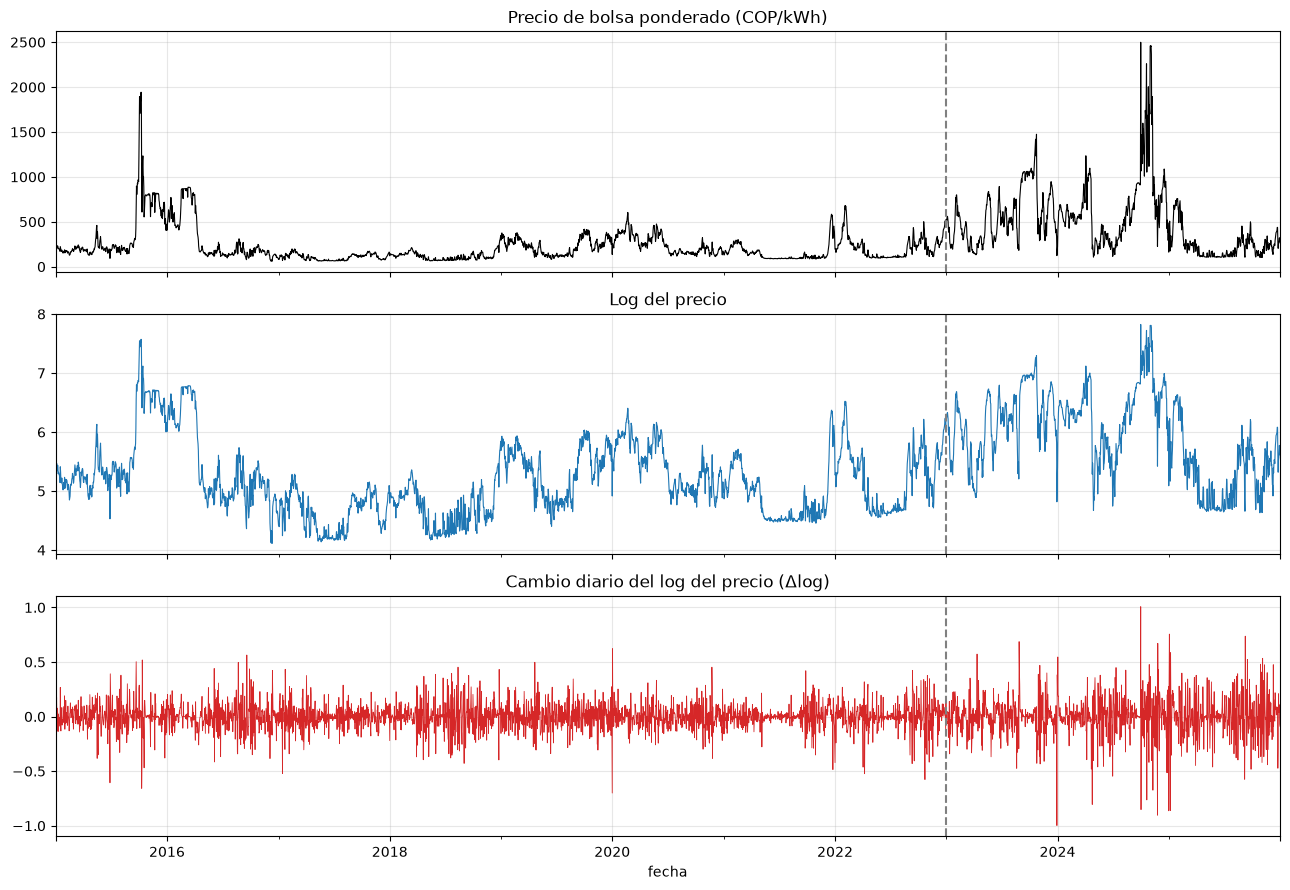

In [4]:
precio = df[OBJETIVO]
log_precio = np.log(precio)
dlog = log_precio.diff()          # cambio diario del log del precio ~ variación porcentual

fig, ax = plt.subplots(3, 1, figsize=(13, 9), sharex=True)
precio.plot(ax=ax[0], color="k", lw=0.8, title="Precio de bolsa ponderado (COP/kWh)")
log_precio.plot(ax=ax[1], lw=0.8, title="Log del precio")
dlog.plot(ax=ax[2], lw=0.6, color="tab:red", title="Cambio diario del log del precio (Δlog)")
for a in ax:
    a.axvline(pd.Timestamp(INICIO_PRUEBA), color="gray", ls="--")
plt.tight_layout()
plt.show()

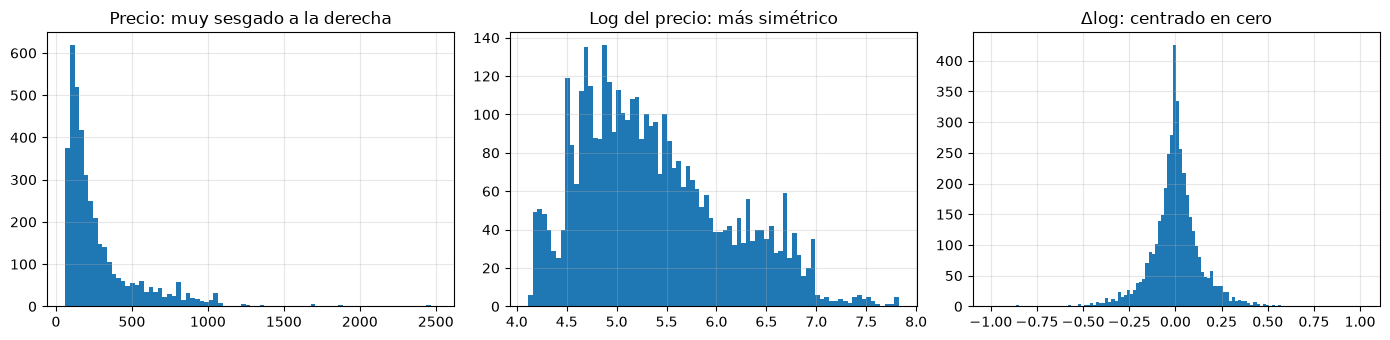

,count,mean,std,min,25%,50%,75%,max
precio_ponderado,4018.0,292.8,277.0,61.2,122.6,190.7,342.2,2498.8


In [5]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.5))
precio.hist(bins=80, ax=ax[0]); ax[0].set_title("Precio: muy sesgado a la derecha")
log_precio.hist(bins=80, ax=ax[1]); ax[1].set_title("Log del precio: más simétrico")
dlog.hist(bins=120, ax=ax[2]); ax[2].set_title("Δlog: centrado en cero")
plt.tight_layout()
plt.show()

precio.describe().round(1).to_frame().T

### ¿Es estacionaria? (prueba ADF)
Los modelos lineales y la selección de variables suponen una serie estable en el tiempo.

La prueba ADF no rechaza la estacionariedad ni siquiera en el nivel, pero el nivel tiene picos enormes (hasta 2.500 COP/kWh) y una varianza que cambia mucho entre años.
Por eso se modela el **cambio diario del log** (Δlog):
- es claramente estacionario y su escala es comparable en todo el periodo;
- obliga al modelo a predecir el *movimiento* del precio, en vez de copiar el precio de ayer.

In [6]:
for nombre, serie in [("precio", precio), ("log precio", log_precio), ("Δlog precio", dlog)]:
    p = adfuller(serie.dropna(), autolag="AIC")[1]
    print(f"{nombre:12s} p-valor ADF = {p:.4f}  ->  {'estacionaria' if p < 0.05 else 'NO estacionaria'}")

precio       p-valor ADF = 0.0004  ->  estacionaria
log precio   p-valor ADF = 0.0063  ->  estacionaria


Δlog precio  p-valor ADF = 0.0000  ->  estacionaria


### Memoria y estacionalidad del cambio diario
La autocorrelación indica qué rezagos del propio precio vale la pena usar como variables.

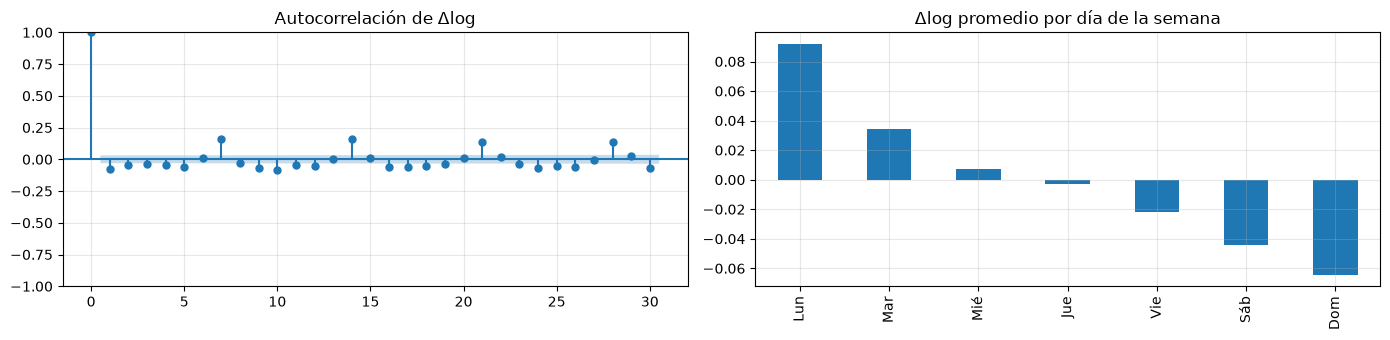

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(14, 3.5))
plot_acf(dlog.dropna(), lags=30, ax=ax[0], title="Autocorrelación de Δlog")
dias = ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"]
dlog.groupby(dlog.index.dayofweek).mean().set_axis(dias).plot.bar(ax=ax[1], title="Δlog promedio por día de la semana")
plt.tight_layout()
plt.show()

### Relación de cada variable con el precio
Correlación de cada variable (medida ayer) con el log del precio de hoy, solo en el periodo de desarrollo.

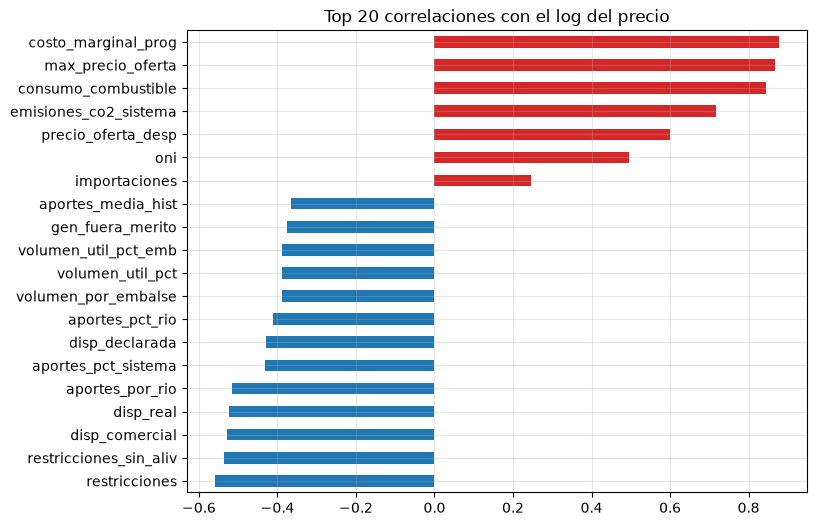

In [8]:
desarrollo = df.loc[:FIN_DESARROLLO]
corr = desarrollo.shift(1).corrwith(np.log(desarrollo[OBJETIVO])).drop(OBJETIVO).dropna()
top = corr.reindex(corr.abs().sort_values(ascending=False).index).head(20)

top.sort_values().plot.barh(figsize=(8, 6), color=np.where(top.sort_values() > 0, "tab:red", "tab:blue"))
plt.title("Top 20 correlaciones con el log del precio")
plt.show()

---
# 2. Ingeniería de características

**Objetivo del modelo:** $y_t = \log(P_t) - \log(P_{t-1})$, el cambio diario del log del precio.
Después, el nivel se reconstruye como $\hat P_t = P_{t-1}\, e^{\hat y_t}$.

**Regla anti-fuga:** para predecir el día $t$ solo se usa información disponible antes de ese día.
- Las variables medidas durante el día (hidrología, demanda, generación…) entran con rezago de **al menos 1 día**.
- Las variables *ex ante*, que se conocen antes del día (precio de escasez, disponibilidad declarada, cargo por confiabilidad, margen de reserva, dummies regulatorias), pueden entrar con rezago 0.
- Las variables de **eventos** (vertimientos, demanda no atendida, importaciones, exportaciones) no tienen ningún cero en los datos de XM: los días sin dato son días **sin evento**, así que se rellenan con 0.
- Se **excluyen** las variables del despacho (`costo_marginal_prog`, `precio_oferta_desp`, `max_precio_oferta`), porque son casi el mismo precio de bolsa.

In [9]:
DESPACHO = ["costo_marginal_prog", "precio_oferta_desp", "max_precio_oferta"]
EX_ANTE = ["precio_escasez", "precio_marg_escasez", "precio_escasez_empalmado", "disp_declarada",
           "enficc", "precio_cargo_conf", "cee", "cere", "mc", "margen_reserva", "dummy_creg_escasez"]
EVENTOS = ["vertimientos", "demanda_no_atendida", "dem_no_atendida_noprog", "importaciones", "exportaciones"]
MAX_FALTANTE = 0.15

panel = df.copy()
panel[EVENTOS] = panel[EVENTOS].fillna(0)      # sin dato = no hubo evento

faltantes_panel = panel.isna().mean()
candidatas = [c for c in panel.columns
              if c != OBJETIVO and c not in DESPACHO and faltantes_panel[c] <= MAX_FALTANTE]
print("Se descartan por faltantes o por ser del despacho:")
print(sorted(set(panel.columns) - set(candidatas) - {OBJETIVO}))

# Relleno hacia adelante: un día sin dato toma el último valor conocido (solo usa el pasado)
base = panel[candidatas].ffill()

# Transformación no lineal: con embalses bajos el precio sube mucho más que proporcionalmente
base["inv_volumen_util_pct"] = 1 / base["volumen_util_pct"].clip(lower=0.02)

ex_ante = [c for c in base.columns if c in EX_ANTE]
ex_post = [c for c in base.columns if c not in EX_ANTE]
print(f"\n{len(ex_ante)} variables ex ante y {len(ex_post)} variables medidas durante el día")

Se descartan por faltantes o por ser del despacho:
['costo_marginal_prog', 'emisiones_co2_sistema', 'irradiacion_global', 'irradiacion_panel', 'max_precio_oferta', 'precio_escasez_act', 'precio_escasez_empalmado', 'precio_escasez_inf', 'precio_escasez_pon', 'precio_marg_escasez', 'precio_oferta_desp', 'temp_ambiente_solar', 'temp_panel']

9 variables ex ante y 36 variables medidas durante el día


### Funciones para crear las características

Para cada variable $x$ se crean tres tipos de características. Todas usan solo información hasta ayer:

| Tipo | Nombre | Qué mide |
|---|---|---|
| Rezago | `x_lag1`, `x_lag2`, `x_lag3`, `x_lag7`, `x_lag14`, `x_lag30` | el valor de hace 1, 2, 3, 7, 14 y 30 días |
| Media móvil | `x_ma7`, `x_ma30` | el nivel "normal" de la última semana y del último mes |
| Choque | `x_choque7`, `x_choque30` | cuánto se alejó el valor de ayer de su media móvil (positivo = por encima de lo normal) |

Las variables *ex ante* tienen además `x_lag0`, el valor del mismo día.

Para el precio se usa su cambio diario (`dlog`): rezagos, volatilidad (`dlog_sd7`, `dlog_sd30`) y choques del log del precio frente a su media móvil (`precio_choque7`, `precio_choque30`).
`precio_choque30` es la misma variable `desv_ma30` de los notebooks anteriores.

In [10]:
LAGS = [1, 2, 3, 7, 14, 30]
VENTANAS = [7, 30]


def crear_lags(datos, columnas, lags):
    # valor de la variable k días atrás
    nuevas = {f"{col}_lag{k}": datos[col].shift(k) for col in columnas for k in lags}
    return pd.DataFrame(nuevas, index=datos.index)


def crear_medias_moviles(datos, columnas, ventanas):
    # promedio de los últimos w días, hasta ayer
    nuevas = {f"{col}_ma{w}": datos[col].shift(1).rolling(w).mean() for col in columnas for w in ventanas}
    return pd.DataFrame(nuevas, index=datos.index)


def crear_choques(datos, columnas, ventanas):
    # valor de ayer menos su media móvil: positivo = por encima de lo normal
    nuevas = {f"{col}_choque{w}": datos[col].shift(1) - datos[col].shift(1).rolling(w).mean()
              for col in columnas for w in ventanas}
    return pd.DataFrame(nuevas, index=datos.index)


def crear_features_precio(log_precio, lags, ventanas):
    dlog = log_precio.diff()
    nuevas = {f"dlog_lag{k}": dlog.shift(k) for k in lags}
    for w in ventanas:
        nuevas[f"dlog_sd{w}"] = dlog.shift(1).rolling(w).std()                                   # volatilidad
        nuevas[f"precio_choque{w}"] = log_precio.shift(1) - log_precio.shift(1).rolling(w).mean()  # reversión a la media
    return pd.DataFrame(nuevas, index=log_precio.index)


def crear_calendario(indice):
    return pd.DataFrame({
        "es_lunes": (indice.dayofweek == 0).astype(int),
        "es_sabado": (indice.dayofweek == 5).astype(int),
        "es_domingo": (indice.dayofweek == 6).astype(int),
    }, index=indice)

In [11]:
X = pd.concat([
    crear_features_precio(log_precio, LAGS, VENTANAS),
    crear_lags(base, ex_ante, [0] + LAGS),
    crear_lags(base, ex_post, LAGS),
    crear_choques(base, base.columns, VENTANAS),
    crear_medias_moviles(base, base.columns, VENTANAS),
    crear_calendario(df.index),
], axis=1)

y = dlog.rename("y")
datos = pd.concat([X, y], axis=1).dropna()   # se pierden los primeros ~60 días (rezago de 30 + ventana de 30)

dev = datos.loc[:FIN_DESARROLLO]
prueba = datos.loc[INICIO_PRUEBA:]
print(f"Características creadas: {X.shape[1]}")
print(f"Desarrollo: {len(dev)} días ({dev.index.min().date()} a {dev.index.max().date()})")
print(f"Prueba:     {len(prueba)} días ({prueba.index.min().date()} a {prueba.index.max().date()})")

Características creadas: 472
Desarrollo: 2891 días (2015-02-01 a 2022-12-31)
Prueba:     1096 días (2023-01-01 a 2025-12-31)


### Limpieza previa a la selección
1. Se quitan variables **constantes** en desarrollo.
2. Se quitan variables **redundantes**: si dos variables tienen correlación mayor a 0.95, se conserva la primera.
   Por ejemplo, `volumen_util_pct_lag1`, `volumen_util_pct_lag2` y `volumen_util_pct_ma7` son casi idénticas.
3. Se quitan las **combinaciones lineales exactas**. Por construcción, `x_choque7 = x_lag1 − x_ma7`: con las tres variables juntas, la regresión no puede separar sus efectos.
   Una variable se conserva solo si agrega información nueva, es decir, si aumenta el rango de la matriz. Como los choques van antes que las medias móviles, se conserva el choque.

In [12]:
def quitar_redundantes(X, umbral=0.95):
    corr = X.corr().abs()
    quitar = set()
    for i, a in enumerate(X.columns):
        if a in quitar:
            continue
        for b in X.columns[i + 1:]:
            if corr.loc[a, b] > umbral:
                quitar.add(b)
    return [c for c in X.columns if c not in quitar]


def quitar_combinaciones_exactas(X):
    Z = ((X - X.mean()) / X.std()).values
    elegidas = []
    for i, c in enumerate(X.columns):
        if np.linalg.matrix_rank(Z[:, elegidas + [i]]) > len(elegidas):
            elegidas.append(i)
    return [X.columns[i] for i in elegidas]


X_dev_todas = dev.drop(columns="y")
no_constantes = X_dev_todas.columns[X_dev_todas.std() > 0]
no_redundantes = quitar_redundantes(X_dev_todas[no_constantes])
COLUMNAS = quitar_combinaciones_exactas(X_dev_todas[no_redundantes])
print(f"{X_dev_todas.shape[1]} creadas -> {len(no_constantes)} sin constantes -> "
      f"{len(no_redundantes)} sin redundantes -> {len(COLUMNAS)} sin combinaciones exactas")

# Estandarizar (media 0, desviación 1) con los parámetros del periodo de desarrollo
escalador = StandardScaler().fit(dev[COLUMNAS])
Xs_dev = pd.DataFrame(escalador.transform(dev[COLUMNAS]), index=dev.index, columns=COLUMNAS)
Xs_prueba = pd.DataFrame(escalador.transform(prueba[COLUMNAS]), index=prueba.index, columns=COLUMNAS)
y_dev, y_prueba = dev["y"], prueba["y"]

472 creadas -> 461 sin constantes -> 258 sin redundantes -> 231 sin combinaciones exactas


---
# 3. Selección de características

Todos los métodos se aplican **solo sobre el periodo de desarrollo** y con modelos lineales.
Al final se comparan las variables que elige cada método.

## 3.1 Selección de variables originales: stepwise

En cada paso se ajusta una regresión lineal (OLS) y se compara el **BIC**. Menor BIC es mejor: premia el ajuste y castiga el número de variables.
- **Forward:** parte del modelo vacío y agrega la variable que más baja el BIC.
- **Backward:** parte del modelo completo y en cada paso quita la variable menos significativa (menor |t|), mientras el BIC siga bajando.
- **Híbrido:** como forward, pero después de cada entrada revisa si alguna variable ya incluida sobra.

In [13]:
def ajustar_ols(X, y, columnas):
    Z = X[columnas].copy()
    Z.insert(0, "const", 1.0)
    return sm.OLS(y, Z).fit()


def forward_stepwise(X, y, criterio="bic"):
    elegidas, restantes = [], list(X.columns)
    mejor = getattr(ajustar_ols(X, y, elegidas), criterio)
    while restantes:
        puntajes = {c: getattr(ajustar_ols(X, y, elegidas + [c]), criterio) for c in restantes}
        candidata = min(puntajes, key=puntajes.get)
        if puntajes[candidata] >= mejor:
            break
        mejor = puntajes[candidata]
        elegidas.append(candidata)
        restantes.remove(candidata)
    return elegidas


def backward_stepwise(X, y, criterio="bic"):
    elegidas = list(X.columns)
    modelo = ajustar_ols(X, y, elegidas)
    while len(elegidas) > 1:
        # la variable menos útil es la de menor |t| (la menos significativa)
        peor = modelo.tvalues.drop("const").abs().idxmin()
        sin_peor = ajustar_ols(X, y, [c for c in elegidas if c != peor])
        if getattr(sin_peor, criterio) > getattr(modelo, criterio):   # si empata, sobra: se quita
            break
        elegidas.remove(peor)
        modelo = sin_peor
    return elegidas


def stepwise_hibrido(X, y, criterio="bic"):
    elegidas = []
    mejor = getattr(ajustar_ols(X, y, elegidas), criterio)
    while True:
        # paso hacia adelante
        restantes = [c for c in X.columns if c not in elegidas]
        if not restantes:
            break
        puntajes = {c: getattr(ajustar_ols(X, y, elegidas + [c]), criterio) for c in restantes}
        candidata = min(puntajes, key=puntajes.get)
        if puntajes[candidata] >= mejor:
            break
        mejor = puntajes[candidata]
        elegidas.append(candidata)
        # paso hacia atrás: ¿alguna de las anteriores ya sobra?
        for c in elegidas[:-1]:
            sin_c = [v for v in elegidas if v != c]
            valor = getattr(ajustar_ols(X, y, sin_c), criterio)
            if valor < mejor:
                mejor, elegidas = valor, sin_c
    return elegidas

In [14]:
sel_forward = forward_stepwise(Xs_dev, y_dev)
sel_backward = backward_stepwise(Xs_dev, y_dev)
sel_hibrido = stepwise_hibrido(Xs_dev, y_dev)

for nombre, sel in [("Forward", sel_forward), ("Backward", sel_backward), ("Híbrido", sel_hibrido)]:
    r2 = ajustar_ols(Xs_dev, y_dev, sel).rsquared
    print(f"{nombre:9s} {len(sel):2d} variables  R² = {r2:.3f}\n          {sel}\n")

Forward   18 variables  R² = 0.224
          ['es_lunes', 'aportes_por_rio_choque30', 'margen_reserva_choque7', 'precio_choque30', 'es_domingo', 'disp_declarada_choque30', 'dlog_lag1', 'aportes_pct_sistema_lag2', 'consumo_combustible_lag3', 'es_sabado', 'volumen_por_embalse_choque7', 'precio_prom_contrato_choque7', 'dlog_lag7', 'dlog_lag14', 'compras_contrato_lag7', 'disp_declarada_lag0', 'disp_declarada_lag2', 'precio_escasez_choque30']

Backward  27 variables  R² = 0.240
          ['dlog_lag1', 'dlog_lag7', 'dlog_lag14', 'precio_choque30', 'cere_lag0', 'disp_declarada_lag0', 'margen_reserva_lag1', 'aportes_media_hist_lag1', 'aportes_media_hist_lag30', 'aportes_pct_sistema_lag2', 'consumo_combustible_lag1', 'disp_comercial_lag1', 'restricciones_lag2', 'volumen_por_embalse_lag1', 'aportes_media_hist_choque7', 'aportes_pct_sistema_choque30', 'compras_contrato_choque30', 'consumo_combustible_choque30', 'demanda_no_regulada_choque30', 'disp_declarada_choque7', 'mc_choque7', 'precio_escase

Resumen del modelo forward. Los coeficientes están estandarizados, así que su tamaño es comparable entre variables:

In [15]:
print(ajustar_ols(Xs_dev, y_dev, sel_forward).summary().tables[1])

                                   coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------------
const                            0.0004      0.002      0.198      0.843      -0.004       0.004
es_lunes                         0.0233      0.002     10.159      0.000       0.019       0.028
aportes_por_rio_choque30        -0.0128      0.003     -5.075      0.000      -0.018      -0.008
margen_reserva_choque7           0.0160      0.002      7.143      0.000       0.012       0.020
precio_choque30                 -0.0253      0.003     -9.704      0.000      -0.030      -0.020
es_domingo                      -0.0129      0.002     -5.455      0.000      -0.018      -0.008
disp_declarada_choque30         -0.0074      0.002     -3.021      0.003      -0.012      -0.003
dlog_lag1                       -0.0154      0.002     -6.696      0.000      -0.020      -0.011
aportes_pct_sistema_lag2      

## 3.2 Selección exhaustiva (best subset)

Evaluar **todas** las combinaciones de cientos de variables es imposible (con 200 serían $2^{200}$ modelos).
Por eso la búsqueda exhaustiva se hace sobre las **12 variables** que eligió el stepwise: $2^{12} - 1 = 4.095$ modelos.
- Para cada tamaño $k$ se guarda el mejor modelo según $R^2$.
- Entre esos mejores modelos se elige el tamaño con menor BIC.

Variables en la búsqueda: ['es_lunes', 'aportes_por_rio_choque30', 'margen_reserva_choque7', 'precio_choque30', 'es_domingo', 'disp_declarada_choque30', 'dlog_lag1', 'aportes_pct_sistema_lag2', 'consumo_combustible_lag3', 'es_sabado', 'volumen_por_embalse_choque7', 'precio_prom_contrato_choque7']


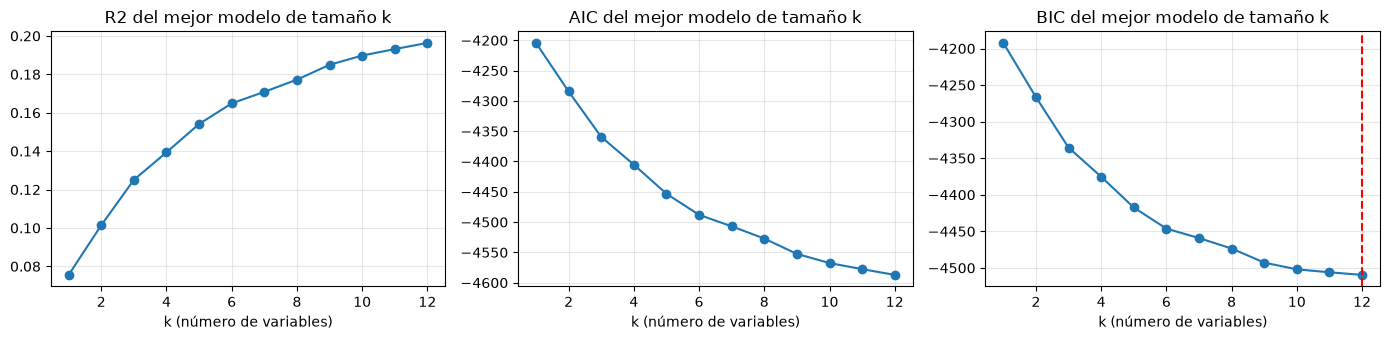

Best subset elige 12 variables: ['es_lunes', 'aportes_por_rio_choque30', 'margen_reserva_choque7', 'precio_choque30', 'es_domingo', 'disp_declarada_choque30', 'dlog_lag1', 'aportes_pct_sistema_lag2', 'consumo_combustible_lag3', 'es_sabado', 'volumen_por_embalse_choque7', 'precio_prom_contrato_choque7']


In [16]:
pool = list(dict.fromkeys(sel_forward + sel_hibrido + sel_backward))[:12]
print("Variables en la búsqueda:", pool)

subconjuntos = []
for k in range(1, len(pool) + 1):
    for combo in combinations(pool, k):
        m = ajustar_ols(Xs_dev, y_dev, list(combo))
        subconjuntos.append({"k": k, "variables": list(combo), "r2": m.rsquared, "aic": m.aic, "bic": m.bic})
subconjuntos = pd.DataFrame(subconjuntos)

mejor_por_k = subconjuntos.loc[subconjuntos.groupby("k")["r2"].idxmax()].set_index("k")
sel_best = mejor_por_k.loc[mejor_por_k["bic"].idxmin(), "variables"]

fig, ax = plt.subplots(1, 3, figsize=(14, 3.5))
for a, col in zip(ax, ["r2", "aic", "bic"]):
    mejor_por_k[col].plot(ax=a, marker="o", title=f"{col.upper()} del mejor modelo de tamaño k")
    a.set_xlabel("k (número de variables)")
ax[2].axvline(mejor_por_k["bic"].idxmin(), color="red", ls="--")
plt.tight_layout()
plt.show()

print(f"Best subset elige {len(sel_best)} variables: {sel_best}")

## 3.3 Métodos de penalización

Se agrega un castigo al tamaño de los coeficientes. La fuerza del castigo ($\alpha$) se elige con validación cruzada temporal.
- **Lasso ($\ell_1$):** lleva coeficientes exactamente a cero, así que **selecciona** variables.
- **Ridge ($\ell_2$):** encoge los coeficientes pero no anula ninguno, así que **no** selecciona. Sirve contra la multicolinealidad.
- **Elastic Net:** mezcla ambos. Selecciona como Lasso y se comporta mejor con grupos de variables correlacionadas.

*Grouped Lasso* no está en scikit-learn y no se usa aquí. Sus grupos serían los bloques temáticos: hidrología, oferta, demanda…

Lasso: alpha = 0.00291, 39 de 231 variables con coeficiente distinto de 0


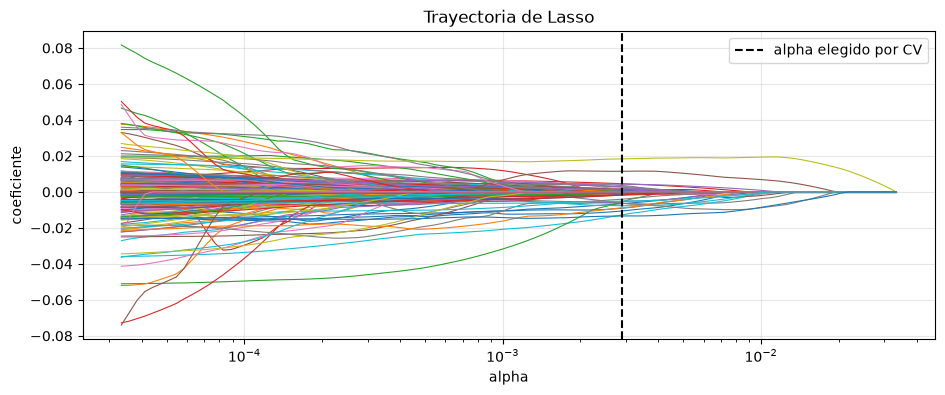

In [17]:
lasso = LassoCV(cv=tscv, max_iter=50000, random_state=0).fit(Xs_dev, y_dev)
coef_lasso = pd.Series(lasso.coef_, index=COLUMNAS)
sel_lasso = coef_lasso[coef_lasso != 0].abs().sort_values(ascending=False).index.tolist()
print(f"Lasso: alpha = {lasso.alpha_:.5f}, {len(sel_lasso)} de {len(COLUMNAS)} variables con coeficiente distinto de 0")

# Trayectoria de los coeficientes: a medida que crece alpha, cada vez más coeficientes llegan a cero
alphas, coefs, _ = lasso_path(Xs_dev, y_dev, n_alphas=100)
plt.figure(figsize=(11, 4))
plt.plot(alphas, coefs.T, lw=0.8)
plt.axvline(lasso.alpha_, color="k", ls="--", label="alpha elegido por CV")
plt.xscale("log"); plt.xlabel("alpha"); plt.ylabel("coeficiente"); plt.legend()
plt.title("Trayectoria de Lasso")
plt.show()

Ridge: alpha = 1689.85, coeficientes exactamente en 0: 0


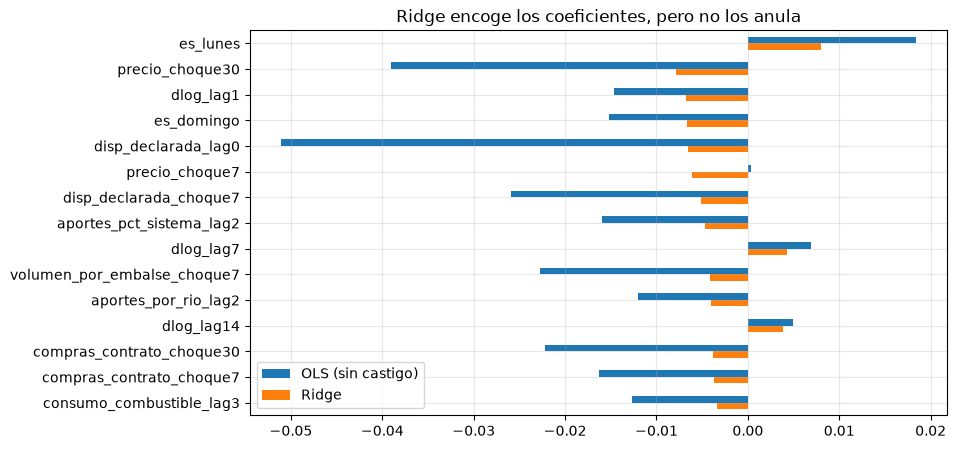

In [18]:
ridge = RidgeCV(alphas=np.logspace(-2, 5, 80), cv=tscv).fit(Xs_dev, y_dev)
coef_ridge = pd.Series(ridge.coef_, index=COLUMNAS)
coef_ols = pd.Series(LinearRegression().fit(Xs_dev, y_dev).coef_, index=COLUMNAS)
print(f"Ridge: alpha = {ridge.alpha_:.2f}, coeficientes exactamente en 0: {(coef_ridge == 0).sum()}")

top = coef_ridge.abs().sort_values(ascending=False).head(15).index
pd.DataFrame({"OLS (sin castigo)": coef_ols[top], "Ridge": coef_ridge[top]}).plot.barh(figsize=(9, 5))
plt.title("Ridge encoge los coeficientes, pero no los anula")
plt.gca().invert_yaxis()
plt.show()

In [19]:
enet = ElasticNetCV(l1_ratio=[0.1, 0.3, 0.5, 0.7, 0.9], cv=tscv, max_iter=50000, random_state=0).fit(Xs_dev, y_dev)
coef_enet = pd.Series(enet.coef_, index=COLUMNAS)
sel_enet = coef_enet[coef_enet != 0].abs().sort_values(ascending=False).index.tolist()
print(f"Elastic Net: alpha = {enet.alpha_:.5f}, l1_ratio = {enet.l1_ratio_}, {len(sel_enet)} variables seleccionadas")

Elastic Net: alpha = 0.02906, l1_ratio = 0.1, 46 variables seleccionadas


## 3.4 Reducción de dimensión: PCR y PLS

En vez de elegir variables originales, se crean **componentes**, que son combinaciones lineales de todas las variables.
- **PCR:** los componentes (PCA) maximizan solo la varianza de $X$, sin mirar $y$ (no supervisado).
- **PLS:** los componentes buscan varianza de $X$ **y** correlación con $y$ (supervisado). Por eso suele necesitar menos componentes.

El número de componentes se elige con validación cruzada temporal.

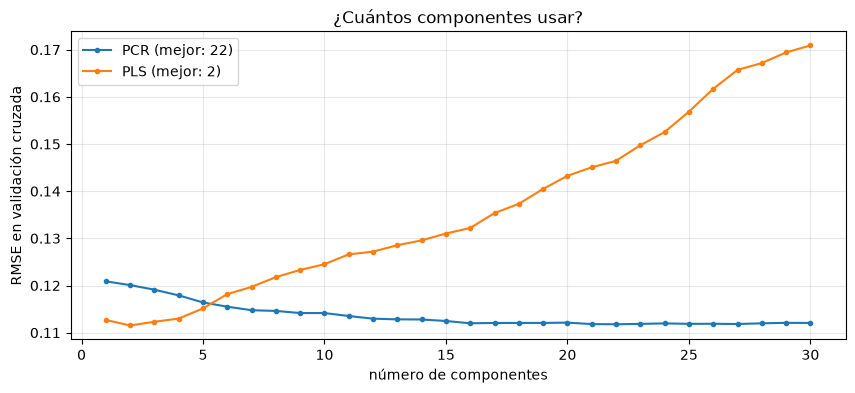

PCR: 22 componentes explican el 66.9% de la varianza de X


In [20]:
def rmse_cv(modelo, X, y):
    return -cross_val_score(modelo, X, y, cv=tscv, scoring="neg_root_mean_squared_error").mean()


n_componentes = range(1, 31)
error_pcr = [rmse_cv(make_pipeline(PCA(n), LinearRegression()), Xs_dev, y_dev) for n in n_componentes]
error_pls = [rmse_cv(PLSRegression(n, scale=False), Xs_dev, y_dev) for n in n_componentes]

n_pcr = n_componentes[int(np.argmin(error_pcr))]
n_pls = n_componentes[int(np.argmin(error_pls))]

plt.figure(figsize=(10, 4))
plt.plot(n_componentes, error_pcr, marker="o", ms=3, label=f"PCR (mejor: {n_pcr})")
plt.plot(n_componentes, error_pls, marker="o", ms=3, label=f"PLS (mejor: {n_pls})")
plt.xlabel("número de componentes"); plt.ylabel("RMSE en validación cruzada"); plt.legend()
plt.title("¿Cuántos componentes usar?")
plt.show()

pca = PCA().fit(Xs_dev)
print(f"PCR: {n_pcr} componentes explican el {100 * pca.explained_variance_ratio_[:n_pcr].sum():.1f}% de la varianza de X")

PCR y PLS no eliminan variables, pero sus *loadings* (pesos) muestran qué variables forman cada componente.
Aquí se ven las variables con más peso en el primer componente de PLS:

In [21]:
pls = PLSRegression(n_pls, scale=False).fit(Xs_dev, y_dev)
pesos_pls = pd.Series(pls.x_weights_[:, 0], index=COLUMNAS)
pesos_pls.reindex(pesos_pls.abs().sort_values(ascending=False).index).head(12).round(3).to_frame("peso componente 1")

,peso componente 1
es_lunes,0.240
compras_contrato_choque7,-0.207
compras_contrato_choque30,-0.194
gen_programada_choque7,-0.188
demanda_no_regulada_choque30,-0.173
gen_programada_choque30,-0.172
es_domingo,-0.167
demanda_regulada_choque7,-0.164
demanda_por_or_choque30,-0.156
margen_reserva_choque7,0.151


## 3.5 Comparación de métodos y conjunto final

Cada método que selecciona variables (stepwise, best subset, Lasso, Elastic Net) aporta un **voto**.
Al XGBoost pasan las variables con **al menos 3 votos de 6**.

In [22]:
metodos = {"Forward": sel_forward, "Backward": sel_backward, "Híbrido": sel_hibrido,
           "Best subset": sel_best, "Lasso": sel_lasso, "Elastic Net": sel_enet}

votos = pd.DataFrame({m: [int(c in s) for c in COLUMNAS] for m, s in metodos.items()}, index=COLUMNAS)
votos["total"] = votos.sum(axis=1)
votos = votos[votos["total"] > 0].sort_values("total", ascending=False)

MIN_VOTOS = 3
FEATURES_FINALES = votos[votos["total"] >= MIN_VOTOS].index.tolist()
print(f"Variables finales ({len(FEATURES_FINALES)}): {FEATURES_FINALES}")
votos

Variables finales (20): ['dlog_lag1', 'precio_choque30', 'aportes_pct_sistema_lag2', 'es_sabado', 'es_domingo', 'es_lunes', 'disp_declarada_lag0', 'aportes_por_rio_choque30', 'dlog_lag7', 'consumo_combustible_lag3', 'precio_escasez_choque30', 'precio_prom_contrato_choque7', 'volumen_por_embalse_choque7', 'margen_reserva_choque7', 'dlog_lag14', 'compras_contrato_lag7', 'mc_choque7', 'compras_contrato_choque30', 'disp_declarada_choque7', 'disp_declarada_lag30']


,Forward,Backward,Híbrido,Best subset,Lasso,Elastic Net,total
dlog_lag1,1,1,1,1,1,1,6
precio_choque30,1,1,1,1,1,1,6
aportes_pct_sistema_lag2,1,1,1,1,1,1,6
es_sabado,1,1,1,1,1,1,6
es_domingo,1,1,1,1,1,1,6
es_lunes,1,1,1,1,1,1,6
disp_declarada_lag0,1,1,1,0,1,1,5
aportes_por_rio_choque30,1,0,1,1,1,1,5
dlog_lag7,1,1,1,0,1,1,5
consumo_combustible_lag3,1,0,1,1,1,1,5


### Desempeño de los modelos lineales en prueba (2023–2025)

Se comparan con un **modelo ingenuo**: el precio de mañana es igual al de hoy ($\hat y = 0$).
- **RMSE / MAE Δlog:** error en el cambio diario.
- **Acierto de dirección:** % de días en que se acierta si el precio sube o baja.
- **MAPE nivel:** error porcentual en COP/kWh, después de reconstruir el precio.

In [23]:
precio_ayer = precio.shift(1).loc[prueba.index]
precio_real = precio.loc[prueba.index]


def evaluar(pred):
    pred = pd.Series(np.ravel(pred), index=prueba.index)
    nivel = precio_ayer * np.exp(pred)
    acierto = np.nan if (pred == 0).all() else 100 * np.mean(np.sign(pred) == np.sign(y_prueba))
    return {"RMSE Δlog": np.sqrt(mean_squared_error(y_prueba, pred)),
            "MAE Δlog": mean_absolute_error(y_prueba, pred),
            "Acierto dirección (%)": acierto,
            "MAPE nivel (%)": 100 * np.mean(np.abs(nivel - precio_real) / precio_real)}


def predecir_ols(columnas):
    m = LinearRegression().fit(Xs_dev[columnas], y_dev)
    return m.predict(Xs_prueba[columnas])


tabla = pd.DataFrame({
    "Ingenuo (precio de ayer)": evaluar(np.zeros(len(prueba))),
    "OLS forward": evaluar(predecir_ols(sel_forward)),
    "OLS backward": evaluar(predecir_ols(sel_backward)),
    "OLS híbrido": evaluar(predecir_ols(sel_hibrido)),
    "OLS best subset": evaluar(predecir_ols(sel_best)),
    "Lasso": evaluar(lasso.predict(Xs_prueba)),
    "Ridge": evaluar(ridge.predict(Xs_prueba)),
    "Elastic Net": evaluar(enet.predict(Xs_prueba)),
    f"PCR ({n_pcr} comp.)": evaluar(make_pipeline(PCA(n_pcr), LinearRegression()).fit(Xs_dev, y_dev).predict(Xs_prueba)),
    f"PLS ({n_pls} comp.)": evaluar(pls.predict(Xs_prueba)),
}).T
tabla.round(4)

,RMSE Δlog,MAE Δlog,Acierto dirección (%),MAPE nivel (%)
Ingenuo (precio de ayer),0.1867,0.1247,NaN,12.8552
OLS forward,0.1659,0.1154,63.9599,12.0360
OLS backward,0.1769,0.1327,59.8540,12.9089
OLS híbrido,0.1659,0.1158,64.1423,12.0666
OLS best subset,0.1685,0.1168,63.2299,11.9552
Lasso,0.1686,0.1160,63.8686,11.9695
Ridge,0.1673,0.1157,62.7737,11.9666
Elastic Net,0.1688,0.1161,63.3212,11.9703
PCR (22 comp.),0.1721,0.1179,63.1387,12.4400
PLS (2 comp.),0.1735,0.1199,61.4051,12.8199


---
# 4. Modelo inicial: XGBoost

Un XGBoost sencillo, con árboles poco profundos y una tasa de aprendizaje baja:
1. Se entrena con 2015–2021 y se usa 2022 para decidir cuántos árboles usar (*early stopping*).
2. Se reentrena con todo el desarrollo (2015–2022) usando ese número de árboles.
3. Se predice la prueba (2023–2025), que el modelo nunca vio.

Se entrenan dos versiones: con las variables seleccionadas y con todas. Así se ve si la selección ayuda.

In [24]:
PARAMS = dict(learning_rate=0.02, max_depth=3, subsample=0.8, colsample_bytree=0.8,
              min_child_weight=5, random_state=42)


def entrenar_xgb(columnas):
    ent, val = dev.loc[:"2021-12-31"], dev.loc["2022-01-01":]
    buscador = xgb.XGBRegressor(n_estimators=3000, early_stopping_rounds=100, **PARAMS)
    buscador.fit(ent[columnas], ent["y"], eval_set=[(val[columnas], val["y"])], verbose=False)
    n_arboles = buscador.best_iteration + 1
    modelo = xgb.XGBRegressor(n_estimators=n_arboles, **PARAMS).fit(dev[columnas], dev["y"])
    print(f"{len(columnas)} variables -> {n_arboles} árboles")
    return modelo


xgb_sel = entrenar_xgb(FEATURES_FINALES)
xgb_todas = entrenar_xgb(COLUMNAS)

pred_xgb = xgb_sel.predict(prueba[FEATURES_FINALES])
tabla.loc["XGBoost (seleccionadas)"] = pd.Series(evaluar(pred_xgb))
tabla.loc["XGBoost (todas)"] = pd.Series(evaluar(xgb_todas.predict(prueba[COLUMNAS])))
tabla.round(4).sort_values("RMSE Δlog")

20 variables -> 421 árboles


231 variables -> 476 árboles


,RMSE Δlog,MAE Δlog,Acierto dirección (%),MAPE nivel (%)
XGBoost (todas),0.1652,0.1143,63.5949,11.8940
XGBoost (seleccionadas),0.1654,0.1137,62.0438,11.8897
OLS forward,0.1659,0.1154,63.9599,12.0360
OLS híbrido,0.1659,0.1158,64.1423,12.0666
Ridge,0.1673,0.1157,62.7737,11.9666
OLS best subset,0.1685,0.1168,63.2299,11.9552
Lasso,0.1686,0.1160,63.8686,11.9695
Elastic Net,0.1688,0.1161,63.3212,11.9703
PCR (22 comp.),0.1721,0.1179,63.1387,12.4400
PLS (2 comp.),0.1735,0.1199,61.4051,12.8199


### Resultados en prueba

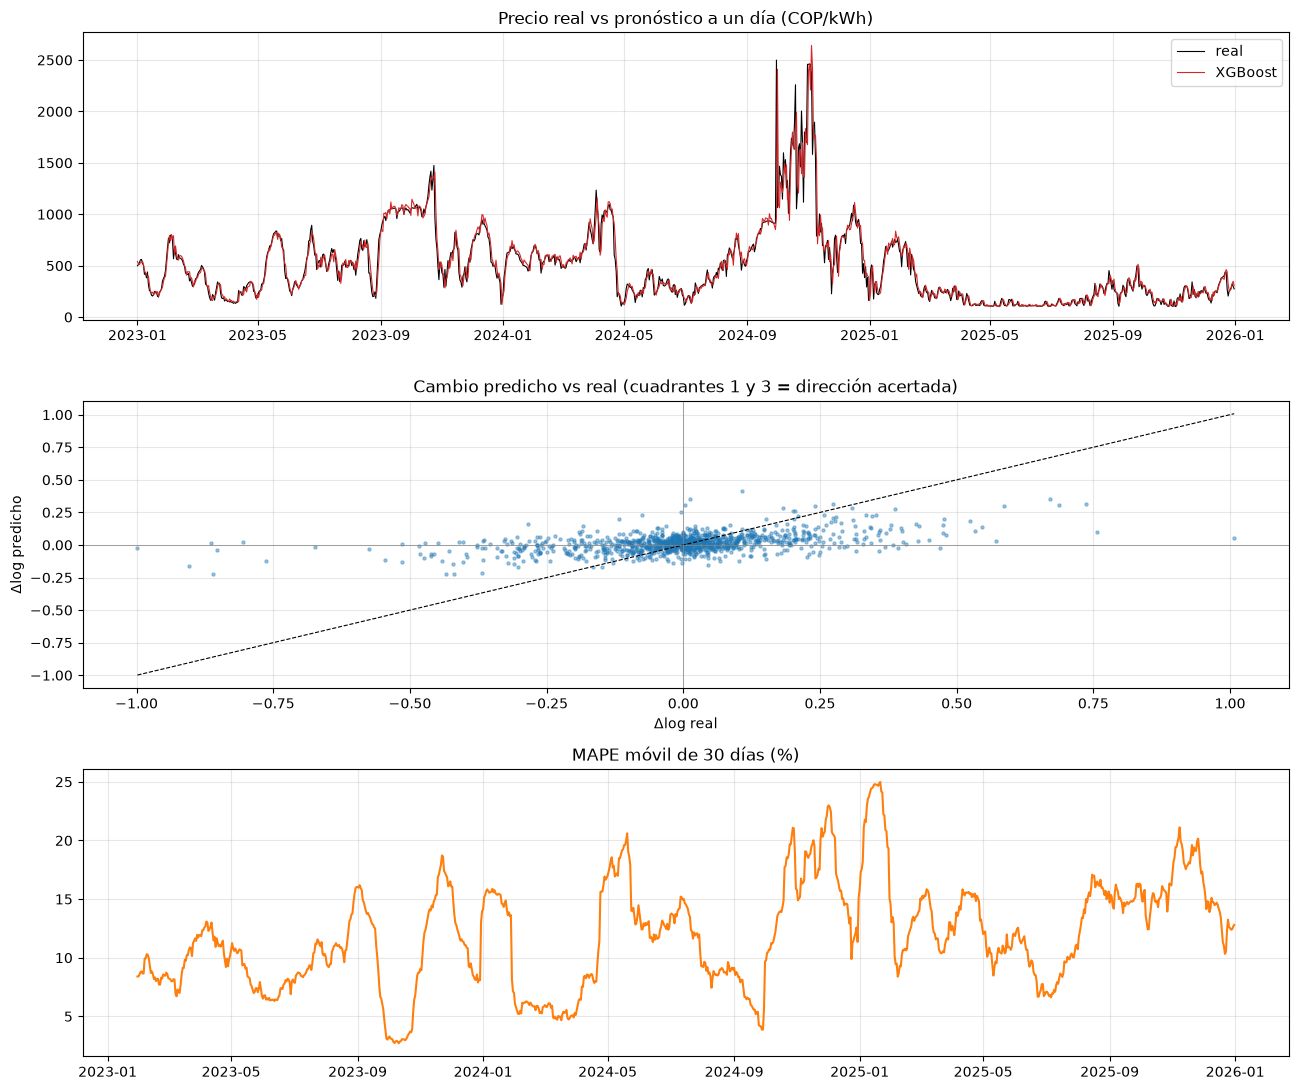

In [25]:
pred_xgb = pd.Series(pred_xgb, index=prueba.index)
nivel_xgb = precio_ayer * np.exp(pred_xgb)
mape_movil = (100 * (nivel_xgb - precio_real).abs() / precio_real).rolling(30).mean()

fig, ax = plt.subplots(3, 1, figsize=(13, 11))
ax[0].plot(precio_real, color="k", lw=0.8, label="real")
ax[0].plot(nivel_xgb, color="tab:red", lw=0.8, label="XGBoost")
ax[0].set_title("Precio real vs pronóstico a un día (COP/kWh)"); ax[0].legend()

ax[1].scatter(y_prueba, pred_xgb, s=5, alpha=0.4)
lim = [y_prueba.min(), y_prueba.max()]
ax[1].plot(lim, lim, "k--", lw=0.8)
ax[1].axhline(0, color="gray", lw=0.5); ax[1].axvline(0, color="gray", lw=0.5)
ax[1].set_xlabel("Δlog real"); ax[1].set_ylabel("Δlog predicho")
ax[1].set_title("Cambio predicho vs real (cuadrantes 1 y 3 = dirección acertada)")

ax[2].plot(mape_movil, color="tab:orange")
ax[2].set_title("MAPE móvil de 30 días (%)")
plt.tight_layout()
plt.show()

### ¿Qué variables usa el modelo?
- **Gain:** medida interna de XGBoost. Cuánto mejora el ajuste cada vez que el árbol usa esa variable.
- **Permutación:** cuánto empeora el error en prueba si se desordena la variable. Es más confiable, porque se mide sobre datos nuevos.

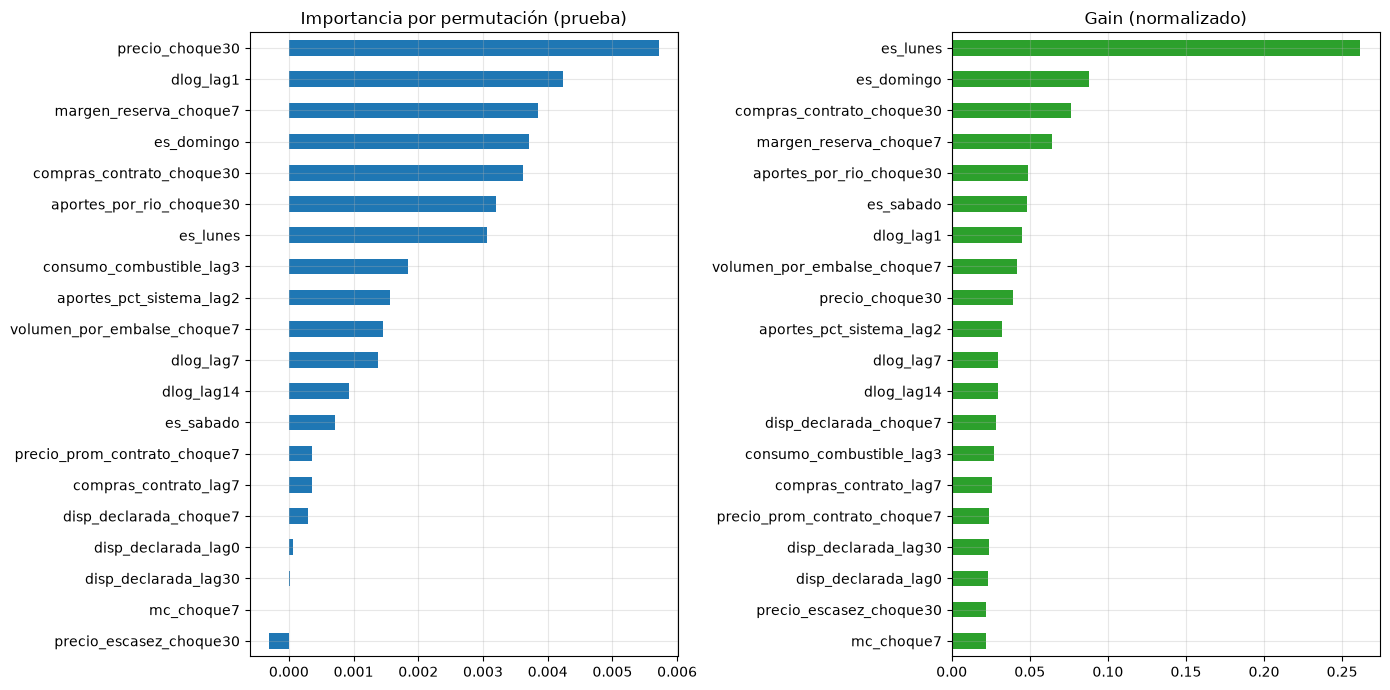

In [26]:
gain = pd.Series(xgb_sel.get_booster().get_score(importance_type="gain")).reindex(FEATURES_FINALES).fillna(0)
perm = permutation_importance(xgb_sel, prueba[FEATURES_FINALES], y_prueba, n_repeats=10, random_state=0,
                              scoring="neg_root_mean_squared_error")
perm = pd.Series(perm.importances_mean, index=FEATURES_FINALES)

fig, ax = plt.subplots(1, 2, figsize=(14, max(4, 0.35 * len(FEATURES_FINALES))))
perm.sort_values().plot.barh(ax=ax[0], color="tab:blue", title="Importancia por permutación (prueba)")
(gain / gain.sum()).sort_values().plot.barh(ax=ax[1], color="tab:green", title="Gain (normalizado)")
plt.tight_layout()
plt.show()

---
# 5. Conclusiones y siguientes pasos

- **Qué se predice:** el cambio diario del log del precio. El nivel en COP/kWh se reconstruye a partir del precio de ayer.
- **Características:** se crearon 472 (rezagos, medias móviles y choques). Tras quitar las constantes, las redundantes y las combinaciones lineales exactas, quedan 231.
- **Los choques son las características más útiles:** 9 de las 20 variables finales son choques. Lo que mueve el precio es que una variable se salga de lo normal, más que su nivel.
- **Los 6 métodos coinciden en un núcleo de variables:**
  - dinámica del precio: `dlog_lag1` y `precio_choque30`, que es la reversión a la media;
  - hidrología: `aportes_pct_sistema_lag2`;
  - calendario: lunes, sábado y domingo.

  Con 5 votos siguen la disponibilidad declarada y los choques de aportes por río, del volumen de los embalses, del margen de reserva y del precio de escasez.
- **Desempeño en prueba (2023–2025):** el XGBoost es el mejor. Baja el RMSE frente al ingenuo de 0,187 a 0,165 (−11%) y el MAPE en nivel de 12,9% a 11,9%. Acierta la dirección del cambio en ~62–64% de los días.
- **La selección funciona:** el XGBoost con 20 variables rinde igual que con las 231.
- **Los lineales quedan cerca:** el OLS forward y el híbrido se quedan a menos de 1% del XGBoost. El backward es el peor, porque parte de 231 variables correlacionadas.

**Siguientes pasos:**
- reentrenar periódicamente, con ventana expansiva;
- ajustar los hiperparámetros del XGBoost con validación temporal;
- mejorar la predicción de los saltos grandes de precio, que es donde crece el error.